In [1]:
#Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Copied these functions from the demand experimentation ipynb
def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)


In [3]:
# rng/seed creator & our record for revenue and customers
rng = np.random.default_rng(100)
record = {"customers": 0, "revenue": 0.0}
tested = []   # every experiment: (price, revenue per customer, customers)

def run(price, n):
    money = sales(price, mean_customers=n, rng=rng) * price
    record["customers"] += len(money)
    record["revenue"] += money.sum()
    tested.append((price, money.mean(), len(money)))
    return money


In [4]:
# copied alot of this gradient estimater from the lab
def estimate_gradient(price, step, n):
    low_price = max(0, price - step)
    high_price = min(70, price + step)
    low = run(low_price, n)
    high = run(high_price, n)
    gap = high_price - low_price
    return (high.mean() - low.mean()) / gap


In [5]:
def gradient_ascent(start_price, rounds, step, n, learning_rate):
    price = start_price
    prices = [price]
    for i in range(rounds):
        gradient = estimate_gradient(price, step, n)
        rate = learning_rate / np.sqrt(i + 1)
        move = np.clip(rate * gradient, -2, 2)
        price = float(np.clip(price + move, 0, 70))
        prices.append(price)
    return prices


In [6]:
# here we are running our 5 climbs and saving the results
starts = np.linspace(5,70,14)
paths = {s: gradient_ascent(s, rounds=20, step=1, n=1000, learning_rate=3.0) for s in starts}
ends = [paths[s][-1] for s in starts]
for s in starts:
    print(f"Start {s} ended at {paths[s][-1]:.2f}")


Start 5.0 ended at 12.29
Start 10.0 ended at 12.23
Start 15.0 ended at 12.22
Start 20.0 ended at 27.50
Start 25.0 ended at 27.61
Start 30.0 ended at 27.27
Start 35.0 ended at 27.74
Start 40.0 ended at 39.84
Start 45.0 ended at 46.81
Start 50.0 ended at 52.46
Start 55.0 ended at 52.03
Start 60.0 ended at 51.23
Start 65.0 ended at 53.28
Start 70.0 ended at 69.68


- I choose to do alot of starts here, I found that while I was writing the code that the more starts I have the more granular and noise-resistant my code was. I know this is more expensive and incurs greater cost but it prevents me from having an adapative n or something like that
- If we adjust our starts low enough we can see that we miss the ideal price of $27.26

In [7]:
results = []
for p in ends:
    money = run(p, 20000)
    results.append({"price": p, "revenue_per_customer": money.mean()})
table = pd.DataFrame(results).sort_values("revenue_per_customer", ascending=False)
print(table.round(3))
chosen = table.iloc[0]["price"]

     price  revenue_per_customer
4   27.608                11.902
3   27.502                11.824
6   27.735                11.824
5   27.275                11.785
0   12.288                11.505
1   12.228                11.484
2   12.220                11.474
10  52.026                 7.743
11  51.233                 7.451
9   52.457                 7.414
12  53.283                 7.354
8   46.809                 6.829
7   39.841                 6.004
13  69.683                 0.021


In [8]:
rpc = record["revenue"] / record["customers"]
print(f"Chosen price: {chosen:.2f}")
print(f"Total customers: {record['customers']:,}")
print(f"Total revenue: ${record['revenue']:,.0f}")
print(f"Revenue per customer: ${rpc:.3f} ({rpc / 11.925:.1%} of optimal)")


Chosen price: 27.61
Total customers: 838,852
Total revenue: $7,078,116
Revenue per customer: $8.438 (70.8% of optimal)


We are seeing the cost here with 0.8m customers required to land at this conclusion.

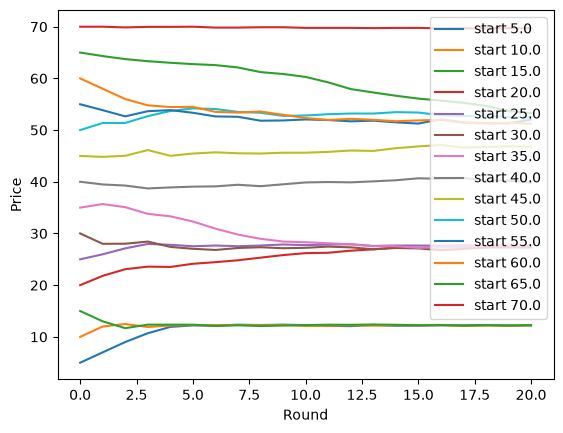

In [9]:
for s in starts:
    plt.plot(paths[s], label=f"start {s}")
plt.xlabel("Round"); plt.ylabel("Price"); plt.legend(); plt.show()

just showing the different peaks that our starts are climbing.

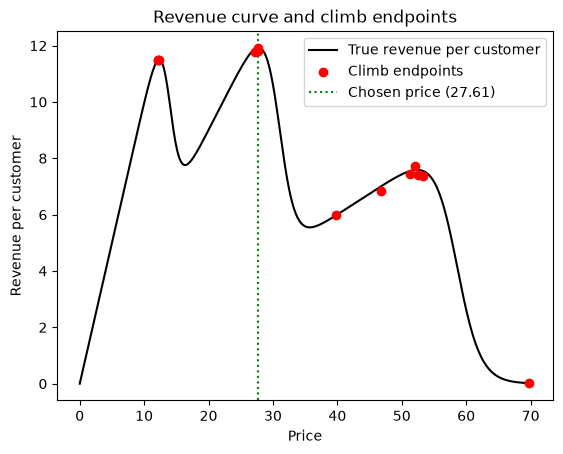

In [10]:
# Diagnostic only: uses the true curve, not part of the search
grid = np.linspace(0, 70, 500)
plt.plot(grid, grid * purchase_probability(grid), color="black", label="True revenue per customer")

# Where the climbs ended, at the revenue they earned in the comparison
plt.scatter(table["price"], table["revenue_per_customer"], color="red", zorder=3, label="Climb endpoints")
plt.axvline(chosen, color="green", linestyle=":", label=f"Chosen price ({chosen:.2f})")

plt.xlabel("Price")
plt.ylabel("Revenue per customer")
plt.title("Revenue curve and climb endpoints")
plt.legend()
plt.show()

claude helped me make this graph - just shows the true shape of our graph and where our different starts either finished or stalled out due to noise.

This is the true curve and not what we calculated earlier (i.e. the testing) in real life a business wouod never know this graph (until they had ran an experiment)

Dont include in the write up - just interesting info

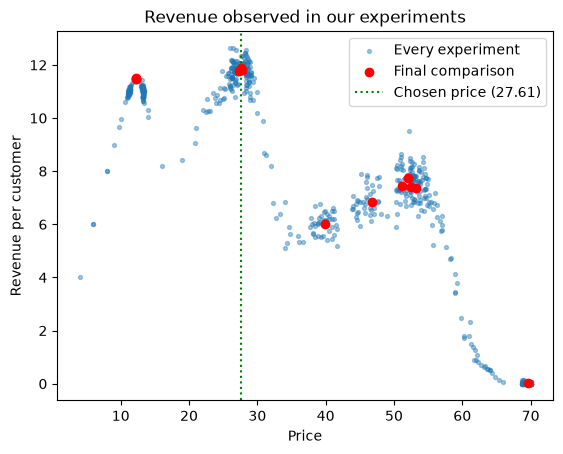

In [11]:
df = pd.DataFrame(tested, columns=["price", "revenue_per_customer", "customers"])

plt.scatter(df["price"], df["revenue_per_customer"], s=8, alpha=0.4, label="Every experiment")
plt.scatter(table["price"], table["revenue_per_customer"], color="red", zorder=3, label="Final comparison")
plt.axvline(chosen, color="green", linestyle=":", label=f"Chosen price ({chosen:.2f})")
plt.xlabel("Price")
plt.ylabel("Revenue per customer")
plt.title("Revenue observed in our experiments")
plt.legend()
plt.show()

Now this is something we should include! When comparing it with the true curve we are seeing alot of similarities and it shows that we had a really through experiment. 

This is the result of our actual searching functions!